# Fixed-dimension change-point models

Does a constant event rate explain the British coal-mining disaster record,
or does a single change point provide a better description? Compare the
constant-rate model $M_0$ with the one-change-point model $M_1$, using an
analytic baseline and a sampled posterior checked against integrated rates.

This notebook uses the bundled public dataset. See [data provenance](../docs/data.md),
[model and sampler sources](../docs/references.md#model-and-sampler-sources), and [references](../docs/references.md).
Install the package using [RUNNING.md](../RUNNING.md) before starting.

In [1]:
from pathlib import Path
import json

import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').is_file() else Path.cwd().parent
if not (ROOT / 'data' / 'coal_intervals_days.csv').is_file():
    raise FileNotFoundError('Run this notebook from the repository root or notebooks directory.')
DATA = ROOT / 'data' / 'coal_intervals_days.csv'
SEED = 1123
from scipy.stats import gamma

from coal_changepoints.data import events_from_intervals, load_intervals
from coal_changepoints.diagnostics import effective_sample_size
from coal_changepoints.model import ChangePointModel
from coal_changepoints.plotting import fixed_model_figure
from coal_changepoints.sampling import sample_m1

intervals = load_intervals(DATA)
events, duration = events_from_intervals(intervals)
model = ChangePointModel(events, duration)
print(f'{len(events)} events; {len(intervals)} intervals; {duration:,.0f} days.')
print(f'Zero-day intervals retained: {np.count_nonzero(intervals == 0)}.')


191 events; 190 intervals; 40,549 days.
Zero-day intervals retained: 1.


## Position priors

Conditional on $k$, the model uses the even-numbered order statistics of
$2k+1$ uniform draws on $(0,L)$. The resulting density is proportional to the
product of the $k+1$ segment lengths. Compared with sorting $k$ uniform draws,
it assigns less mass to very short segments.

The simulation below compares these two priors for $k=3$. Only the
even-order-statistic prior is used in the inference that follows.

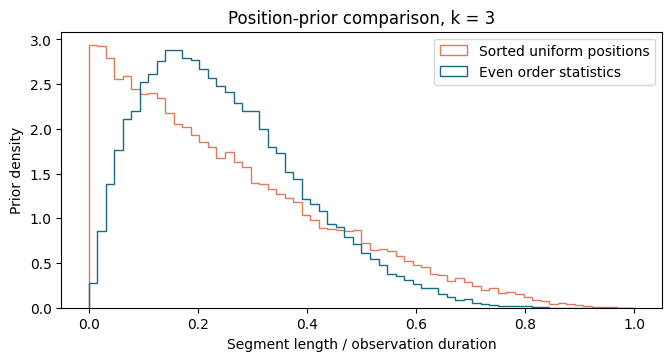

In [2]:
prior_rng = np.random.default_rng(SEED)
k = 3
n_prior_draws = 10000
plain_positions = np.sort(prior_rng.uniform(size=(n_prior_draws, k)), axis=1)
even_positions = np.sort(prior_rng.uniform(size=(n_prior_draws, 2 * k + 1)), axis=1)[:, 1::2]
plain_gaps = np.diff(np.column_stack([np.zeros(n_prior_draws), plain_positions, np.ones(n_prior_draws)]), axis=1)
even_gaps = np.diff(np.column_stack([np.zeros(n_prior_draws), even_positions, np.ones(n_prior_draws)]), axis=1)

fig, ax = plt.subplots(figsize=(6.6, 3.5), constrained_layout=True)
bins = np.linspace(0, 1, 65)
ax.hist(plain_gaps.ravel(), bins=bins, density=True, histtype='step', label='Sorted uniform positions', color='#e07a5f')
ax.hist(even_gaps.ravel(), bins=bins, density=True, histtype='step', label='Even order statistics', color='#176b87')
ax.set(xlabel='Segment length / observation duration', ylabel='Prior density', title='Position-prior comparison, k = 3')
ax.legend()
display(fig)
plt.close(fig)


## Constant-rate baseline

With $h\sim\mathrm{Gamma}(\alpha,\beta)$ in the **shape–rate** convention,
$h\mid y,M_0\sim\mathrm{Gamma}(\alpha+N,\beta+L)$. The defaults are
$\alpha=1$ and $\beta=200$ days. Both endpoint events are included in $N$.

The evidence integrates the rate analytically. It is conditional on $M_0$;
the prior probability of the model is not included.

In [3]:
posterior_shape, posterior_rate = model.constant_posterior()
posterior_m0 = gamma(a=posterior_shape, scale=1 / posterior_rate)
log_z0 = model.log_evidence_m0()
print(json.dumps({
    'posterior_shape': posterior_shape,
    'posterior_rate_days': posterior_rate,
    'mean_events_per_day': posterior_m0.mean(),
    'central_95_percent_interval_per_day': posterior_m0.ppf([0.025, 0.975]).tolist(),
    'log_evidence_m0': log_z0,
}, indent=2))


{
  "posterior_shape": 192.0,
  "posterior_rate_days": 40749.0,
  "mean_events_per_day": 0.004711772068026209,
  "central_95_percent_interval_per_day": [
    0.004068839413925193,
    0.005401174456005629
  ],
  "log_evidence_m0": -1217.0877693997372
}


## One change point

Alternate exact Gamma draws for the two segment rates with a Gaussian
Metropolis step for the change-point position. A proposal outside $(0,L)$ is
rejected. The fixed seed, 5,000 burn-in updates and 20,000 retained draws make
this example reproducible.

Independently integrating both rates and then the position gives a reference
evidence and a marginal position CDF. This reference checks the sampled
posterior without relying on a histogram-derived evidence estimate.

In [4]:
m1_chain, position_acceptance = sample_m1(
    model, np.random.default_rng(SEED), burn=5000, n_samples=20000,
)
log_z1 = model.log_evidence_m1()
log_bayes_factor = log_z1 - log_z0
print(json.dumps({
    'retained_draws': len(m1_chain),
    'position_acceptance': position_acceptance,
    'log_evidence_m1': log_z1,
    'log_bayes_factor_m1_over_m0': log_bayes_factor,
    'log_posterior_odds_m1_over_m0': log_bayes_factor + np.log(model.lam),
}, indent=2))


{
  "retained_draws": 20000,
  "position_acceptance": 0.5742,
  "log_evidence_m1": -1187.3438765790288,
  "log_bayes_factor_m1_over_m0": 29.743892820708425,
  "log_posterior_odds_m1_over_m0": 30.842505109376535
}


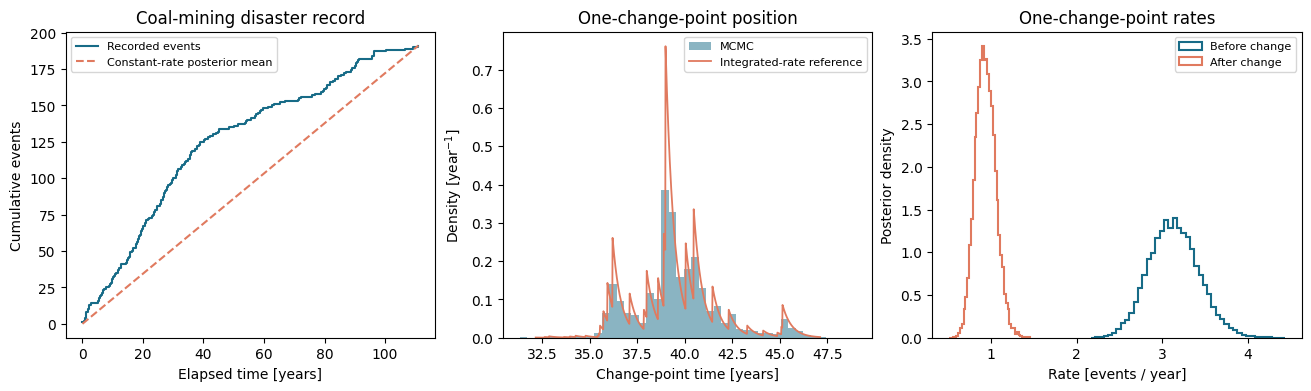

In [5]:
fig = fixed_model_figure(model, m1_chain)
display(fig)
plt.close(fig)


## Sampling checks and interpretation

Compare the integrated-reference CDF with the empirical CDF at the sampled
25th, 50th and 75th percentiles. Effective sample sizes describe autocorrelation
in this single chain; they do not establish convergence. The displayed year
axis uses elapsed days divided by 365.25, rather than exact calendar dates.

In [6]:
quantiles = np.array([0.25, 0.5, 0.75])
positions = np.quantile(m1_chain[:, 0], quantiles)
reference_cdf = np.exp([model.log_evidence_m1(upper=float(s)) - log_z1 for s in positions])
ess = {name: float(effective_sample_size(m1_chain[:, column]))
       for column, name in enumerate(('position', 'rate_before', 'rate_after'))}
print('Empirical quantile  Position [days]  Reference CDF')
for q, s, cdf in zip(quantiles, positions, reference_cdf):
    print(f'{q:18.2f}  {s:15.1f}  {cdf:13.4f}')
print('Effective sample sizes:', {name: round(value) for name, value in ess.items()})


Empirical quantile  Position [days]  Reference CDF
              0.25          14083.2         0.2670
              0.50          14370.3         0.5158
              0.75          14838.9         0.7556
Effective sample sizes: {'position': 709, 'rate_before': 6970, 'rate_after': 8576}


The evidence comparison concerns these specified priors and the Poisson
process model. It does not identify a cause of any rate change. The model
omits time-varying exposure, reporting practices and other possible sources of
overdispersion. Continue with [reversible-jump inference](02_reversible_jump.ipynb)
to allow uncertainty in the number of change points.